In [2]:
import gzip
import pandas as pd
from lxml import etree


decode pop and household files

In [12]:

path = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_population.xml.gz"

# 1) Quick peek at the raw file (first 50 lines)
with gzip.open(path, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        print(line.rstrip())
        if i >= 200:
            break

path = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_households.xml.gz"


# 1) Quick peek at the raw file (first 50 lines)
with gzip.open(path, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        print(line.rstrip())
        if i >= 200:
            break

<?xml version="1.0" encoding="utf-8"?>
<!DOCTYPE population SYSTEM "http://www.matsim.org/files/dtd/population_v6.dtd">

<population desc="Switzerland Baseline">

	<attributes>
		<attribute name="coordinateReferenceSystem" class="java.lang.String">Atlantis</attribute>
	</attributes>


<!-- ====================================================================== -->

	<person id="10000901">
		<attributes>
			<attribute name="age" class="java.lang.Integer">37</attribute>
			<attribute name="bikeAvail" class="java.lang.String">always</attribute>
			<attribute name="cantonId" class="java.lang.Double">-1.0</attribute>
			<attribute name="cantonName" class="java.lang.String">fr</attribute>
			<attribute name="carASC" class="java.lang.Double">0.03</attribute>
			<attribute name="carAvail" class="java.lang.String">always</attribute>
			<attribute name="carOwnershipRatio" class="java.lang.Double">0.0</attribute>
			<attribute name="employed" class="java.lang.Boolean">true</attribute>
			<attribut

In [4]:
path = r"working_rep\filterred_data\lausanne_households_filtered.xml.gz"


# 1) Quick peek at the raw file (first 50 lines)
with gzip.open(path, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        print(line.rstrip())
        if i >= 200:
            break

<?xml version="1.0" encoding="UTF-8"?>

<households xmlns="http://www.matsim.org/files/dtd" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.matsim.org/files/dtd http://www.matsim.org/files/dtd/households_v1.0.xsd">
	<household id="2918360">
		<members>
			<personId refId="6560858" />
			<personId refId="6560859" />
		</members>
		<income currency="CHF" period="month">
				12000.0
		</income>
		<attributes>
			<attribute name="cantonId" class="java.lang.Double">22.0</attribute>
			<attribute name="cantonName" class="java.lang.String">vaud</attribute>
			<attribute name="incomeClass" class="java.lang.Integer">5</attribute>
			<attribute name="incomePerCapita" class="java.lang.Double">7333.333333333333</attribute>
			<attribute name="municipalityType" class="java.lang.String">urbancore</attribute>
			<attribute name="numberOfCars" class="java.lang.String">1</attribute>
			<attribute name="ovgk" class="java.lang.String">A</attribute>
			<attribute name=

initiate data

In [19]:
pop_path = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_population.xml.gz"
hh_path  = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_households.xml.gz"

Understanding id behaviour

In [ ]:
'''Compare population file and household file ids 
'''

import gzip
import xml.etree.ElementTree as ET

pop_path = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_population.xml.gz"
hh_path  = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_households.xml.gz"

OFFSET = 10_000_000


def get_population_ids(path):
    """Collect <person id="..."> from the population file."""
    ids = []
    with gzip.open(path, "rb") as f:
        # Only listen for 'start' of person elements; skip everything else
        for event, elem in ET.iterparse(f, events=("start",)):
            if elem.tag == "person":
                ids.append(elem.attrib["id"])
            # NOTE: don't clear on 'start'; the tree is tiny since we only keep ids
    return ids


def get_household_person_ids(path):
    """Collect <personId refId="..."/> from the households file (namespace-safe)."""
    ids = []
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("end",)):
            tag = elem.tag.split("}")[-1]  # strip xmlns if present
            if tag == "personId":
                ids.append(elem.attrib["refId"])
            elif tag == "household":
                elem.clear()  # free memory
    return ids


pop_ids = get_population_ids(pop_path)
hh_ids = get_household_person_ids(hh_path)

pop_set, hh_set = set(pop_ids), set(hh_ids)

print(f"Population persons:      {len(pop_ids):,} ({len(pop_set):,} unique)")
print(f"Household person refs:   {len(hh_ids):,} ({len(hh_set):,} unique)")

# --- Comparison 1: raw ids ---
raw_common = pop_set & hh_set
print("\n=== Raw comparison (pop id vs hh id) ===")
print(f"In both:             {len(raw_common):,}")
print(f"Only in population:  {len(pop_set - hh_set):,}")
print(f"Only in households:  {len(hh_set - pop_set):,}")

# --- Comparison 2: population id - 10,000,000 vs household id ---
def shift(pid):
    try:
        return str(int(pid) - OFFSET)
    except ValueError:
        return None  # non-numeric id, can't shift

pop_shifted = {}
non_numeric = []
for pid in pop_set:
    s = shift(pid)
    if s is None:
        non_numeric.append(pid)
    else:
        pop_shifted[s] = pid  # shifted -> original

shifted_set = set(pop_shifted)
shift_common = shifted_set & hh_set

print(f"\n=== Shifted comparison (pop id - {OFFSET:,} vs hh id) ===")
print(f"Matched:                              {len(shift_common):,}")
print(f"Pop (shifted) not in households:      {len(shifted_set - hh_set):,}")
print(f"Households not in pop (shifted):      {len(hh_set - shifted_set):,}")
if non_numeric:
    print(f"Non-numeric population ids skipped:   {len(non_numeric):,}")

# --- Duplicates check (useful for validation) ---
from collections import Counter
dup_pop = [k for k, v in Counter(pop_ids).items() if v > 1]
dup_hh  = [k for k, v in Counter(hh_ids).items() if v > 1]
print(f"\nDuplicate pop ids: {len(dup_pop):,} | duplicate household member refs: {len(dup_hh):,}")

# --- Peek at examples of mismatches ---
print("\nExamples only in households (vs shifted pop):", sorted(hh_set - shifted_set)[:10])
print("Examples only in population (shifted):", sorted(shifted_set - hh_set)[:10])

Population persons:      62,336 (62,336 unique)
Household person refs:   53,442 (53,442 unique)

=== Raw comparison (pop id vs hh id) ===
In both:             53,442
Only in population:  8,894
Only in households:  0

=== Shifted comparison (pop id - 10,000,000 vs hh id) ===
Matched:                              0
Pop (shifted) not in households:      53,442
Households not in pop (shifted):      53,442
Non-numeric population ids skipped:   8,894

Duplicate pop ids: 0 | duplicate household member refs: 0

Examples only in households (vs shifted pop): ['10000901', '10002135', '10002202', '10002205', '10002640', '10002761', '10003447', '10003448', '10003449', '10003704']
Examples only in population (shifted): ['-1000043', '-1004537', '-1009915', '-1022950', '-1024681', '-102847', '-1039030', '-1047946', '-1070300', '-107218']


basic comparaison between the unfiltered files

MATSim: 62336 persons, 53442 with valid age and sex
Mikrozensus read with encoding: cp1252
Mikrozensus: 57090 persons, 57090 with valid age and sex


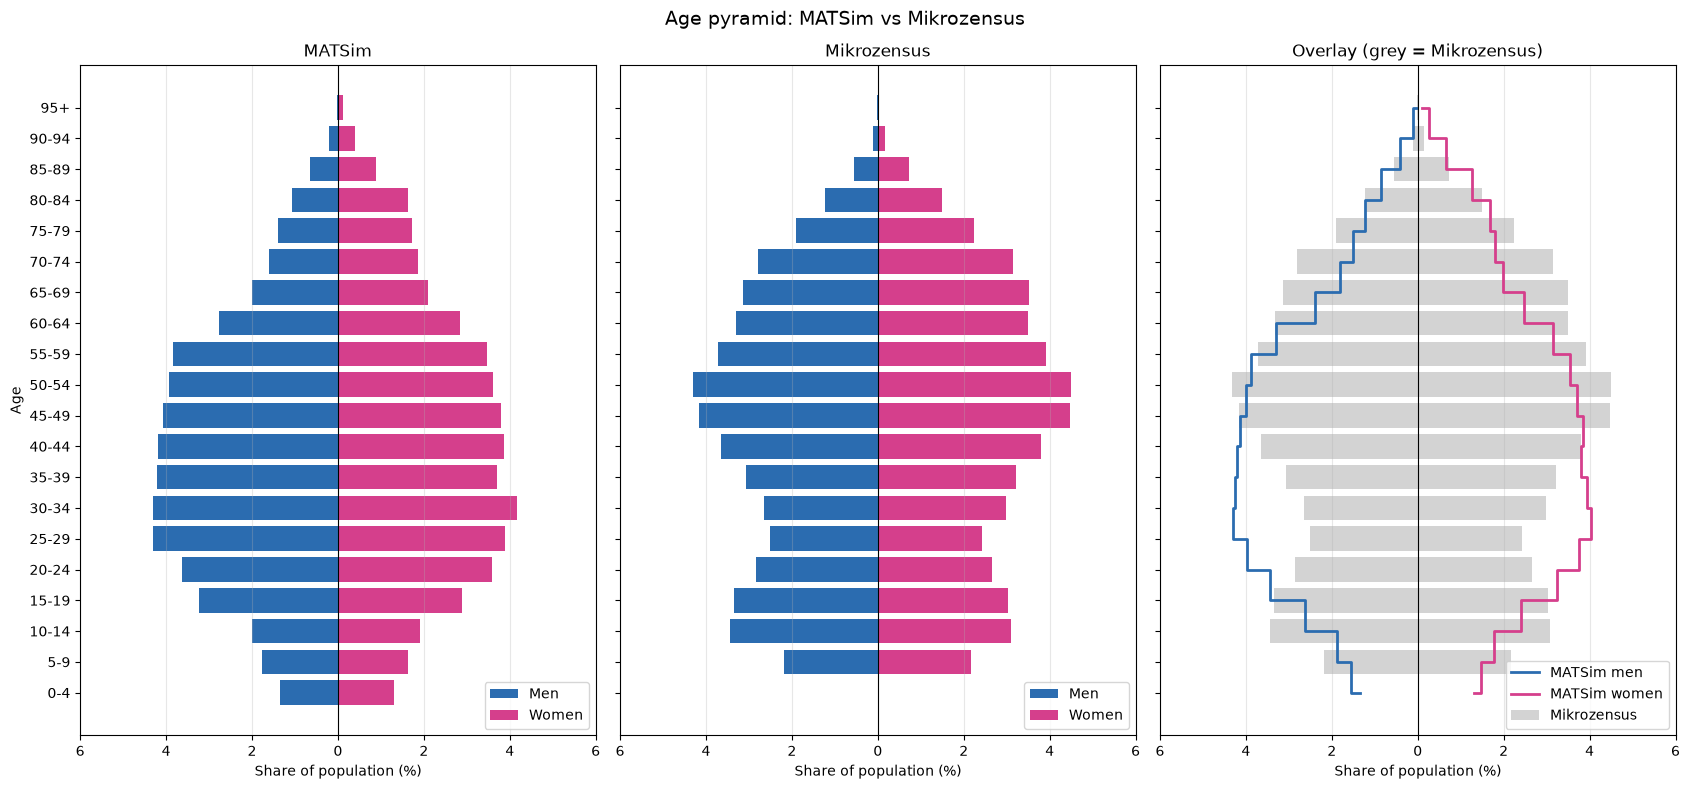

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [ ]:
#"""
#Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)
#Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
#"""
#import gzip
#from pathlib import Path
#import xml.etree.ElementTree as ET
#
#import numpy as np
#import pandas as pd
#import matplotlib.pyplot as plt
#
## ------------------------------------------------------------------ paths
#MATSIM_PATH = Path("Lausanne_10pct/Lausanne_10pct/Lausanne_10pct/Lausanne_10pct/lausanne_population.xml.gz")
#MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
#OUT_DIR = Path("working_rep/validation")
#OUT_DIR.mkdir(parents=True, exist_ok=True)
#
#BIN_WIDTH = 5
#MAX_AGE = 100
#BINS = list(range(0, MAX_AGE + BIN_WIDTH, BIN_WIDTH))
#LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]
#
#
## ------------------------------------------------------------------ MATSim
#def read_matsim(path):
#    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
#    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
#    rows = []
#    person = None
#    in_plan = False
#    with gzip.open(path, "rb") as f:
#        for event, elem in ET.iterparse(f, events=("start", "end")):
#            tag = elem.tag
#            if event == "start":
#                if tag == "person":
#                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
#                elif tag == "plan":
#                    in_plan = True
#            else:
#                if tag == "attribute" and person is not None and not in_plan:
#                    name = elem.get("name")
#                    if name in ("age", "sex", "gender"):
#                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
#                elif tag == "plan":
#                    in_plan = False
#                    elem.clear()
#                elif tag == "person":
#                    rows.append(person)
#                    person = None
#                    elem.clear()
#    df = pd.DataFrame(rows)
#    df["age"] = pd.to_numeric(df["age"], errors="coerce")
#    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
#    n0 = len(df)
#    df = df.dropna(subset=["age", "sex"])
#    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
#    return df
#
#
## ------------------------------------------------------------------ Mikrozensus
#def read_mz(path):
#    for enc in ("utf-8", "cp1252", "latin-1"):
#        try:
#            df = pd.read_csv(path, sep=None, engine="python",
#                             usecols=["alter", "gesl"], encoding=enc)
#            print(f"Mikrozensus read with encoding: {enc}")
#            break
#        except UnicodeDecodeError:
#            continue
#    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
#    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
#    n0 = len(df)
#    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])  # drop negative missing codes
#    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")
#    return df[["age", "sex"]]
#
#
## ------------------------------------------------------------------ helpers
#def shares(df):
#    """% of total population per age bin and sex."""
#    ages = df["age"].clip(upper=MAX_AGE)
#    cut = pd.cut(ages, bins=BINS, right=False, labels=LABELS)
#    tab = pd.crosstab(cut, df["sex"]).reindex(LABELS, fill_value=0)
#    for s in ("m", "f"):
#        if s not in tab:
#            tab[s] = 0
#    return tab[["m", "f"]] / len(df) * 100
#
#
#def plot(mat, mz):
#    y = np.arange(len(LABELS))
#    xmax = max(mat.values.max(), mz.values.max()) * 1.1
#    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)
#
#    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
#        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
#        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
#        ax.set_title(title)
#
#    # overlay comparison
#    ax = axes[2]
#    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
#    ax.barh(y, mz["f"], color="lightgrey")
#    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
#    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
#    ax.set_title("Overlay (grey = Mikrozensus)")
#
#    for ax in axes:
#        ax.set_xlim(-xmax, xmax)
#        ax.set_yticks(y)
#        ax.set_yticklabels(LABELS)
#        ax.set_xticks(ax.get_xticks())
#        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
#        ax.set_xlabel("Share of population (%)")
#        ax.axvline(0, color="black", lw=0.8)
#        ax.grid(axis="x", alpha=0.3)
#        ax.legend(loc="lower right")
#    axes[0].set_ylabel("Age")
#    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
#    fig.tight_layout()
#    fig.savefig(OUT_DIR / "age_pyramid.png", dpi=200)
#    plt.show()
#
#
## ------------------------------------------------------------------ main
#if __name__ == "__main__":
#    matsim = read_matsim(MATSIM_PATH)
#    mz = read_mz(MZ_PATH)
#
#    s_mat, s_mz = shares(matsim), shares(mz)
#
#    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
#    out.columns = [f"{a}_{b}" for a, b in out.columns]
#    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
#    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
#    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")
#
#    plot(s_mat, s_mz)
#    print(f"Saved to {OUT_DIR.resolve()}")

In [9]:
for enc in ("utf-8", "cp1252", "latin-1"):
    try:
        mz_raw = pd.read_csv(MZ_PATH, sep=None, engine="python",
                             usecols=["alter", "gesl"], encoding=enc)
        break
    except UnicodeDecodeError:
        continue

print("Unique gesl values:", sorted(mz_raw["gesl"].dropna().unique()))
print(mz_raw["gesl"].value_counts(dropna=False).sort_index())

Unique gesl values: [np.int64(1), np.int64(2)]
gesl
1    27943
2    29147
Name: count, dtype: int64


Map of all population in matsim adresses

53442


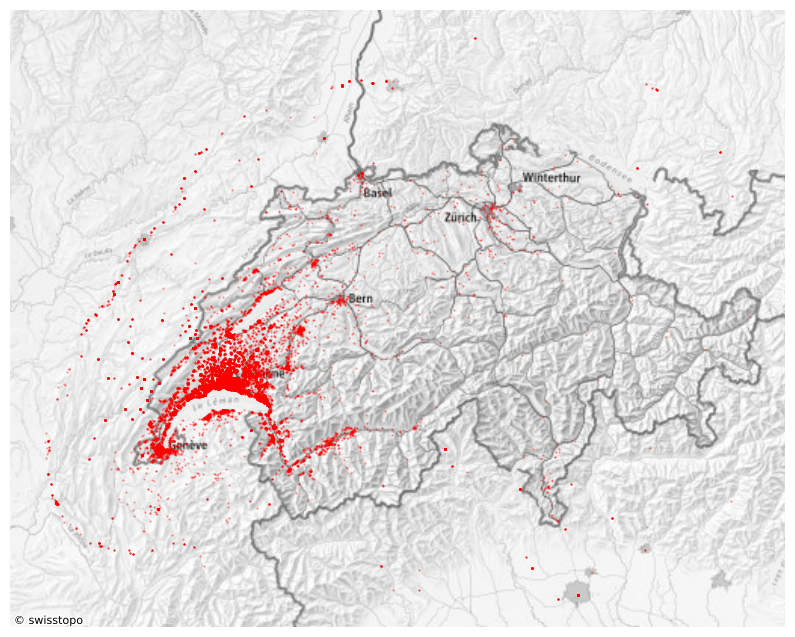

In [30]:
import gzip
import xml.etree.ElementTree as ET
import pandas as pd

pop_path = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_population.xml.gz"

rows = []
with gzip.open(pop_path, "rb") as f:
    for event, elem in ET.iterparse(f, events=("end",)):
        if elem.tag == "person":
            attrs = {a.get("name"): a.text for a in elem.iter("attribute")}
            if "home_coordinate_x" in attrs and "home_coordinate_y" in attrs:
                rows.append({
                    "person_id": elem.get("id"),
                    "x": float(attrs["home_coordinate_x"]),
                    "y": float(attrs["home_coordinate_y"]),
                })
            elem.clear()  # free memory

df = pd.DataFrame(rows)
print(len(df))
df.head()

# pip install geopandas contextily
import geopandas as gpd
import contextily as cx

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y), crs="EPSG:2056")
gdf_web = gdf.to_crs(epsg=3857)


ax = gdf_web.plot(markersize=0.3, alpha=0.4, figsize=(10, 10), color="red")
cx.add_basemap(
    ax,
    source="https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/default/current/3857/{z}/{x}/{y}.jpeg",
    crs=gdf_web.crs,
    attribution="© swisstopo",
)
ax.set_axis_off()

Unique function for .xml.gz files

In [ ]:
''' all the different matsim municipality typse'''
import gzip
from collections import Counter
import xml.etree.ElementTree as ET

path = r"working_rep\filterred_data\lausanne_population_filtered.xml.gz"

counts = Counter()
n_hh = 0
hh_has_type = False

with gzip.open(path, "rb") as f:
    for event, elem in ET.iterparse(f, events=("start", "end")):
        tag = elem.tag.rsplit("}", 1)[-1]          # ignore XML namespace
        if event == "start" and tag == "household":
            n_hh += 1
            hh_has_type = False
        elif event == "end":
            if tag == "attribute" and elem.get("name") == "municipalityType":
                counts[(elem.text or "").strip()] += 1
                hh_has_type = True
            elif tag == "household":
                if not hh_has_type:
                    counts["<missing>"] += 1
                elem.clear()

print(f"{n_hh} households")
for value, n in counts.most_common():
    print(f"{value!r:20} {n:8d}  ({n / n_hh:.1%})")

In [5]:
import gzip
from collections import Counter
import xml.etree.ElementTree as ET

path = r"working_rep\filterred_data\lausanne_population_filtered.xml.gz"

counts = Counter()
n_activities = 0

with gzip.open(path, "rb") as f:
    for event, elem in ET.iterparse(f, events=("end",)):
        tag = elem.tag.rsplit("}", 1)[-1]          # ignore XML namespace
        if tag == "activity":
            n_activities += 1
            counts[elem.get("type", "<missing>")] += 1
            elem.clear()                            # free memory

print(f"{n_activities} activities")
for value, n in counts.most_common():
    print(f"{value!r:20} {n:10d}  ({n / n_activities:.1%})")

358561 activities
'car interaction'         89610  (25.0%)
'home'                    83640  (23.3%)
'pt interaction'          73236  (20.4%)
'car_passenger interaction'      21728  (6.1%)
'outside'                 19374  (5.4%)
'leisure'                 18137  (5.1%)
'work'                    13710  (3.8%)
'shop'                    11528  (3.2%)
'other'                   10992  (3.1%)
'education'                6888  (1.9%)
'bike interaction'         6208  (1.7%)
'work_secondary'           2625  (0.7%)
'home_secondary'            724  (0.2%)
'education_secondary'        161  (0.0%)


In [9]:
df = pd.read_csv(
    r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv",
    encoding="latin1"
)

df["HHNR"].value_counts()

HHNR
397884    21
357004    18
175486    17
331978    17
135454    16
          ..
499503     1
499562     1
499819     1
499969     1
499998     1
Name: count, Length: 50782, dtype: int64